<br />
<div style="text-align: center;">
<font size="5">数式処理 group work：SymPyのQR回帰からNumPyのSVD・主成分分析へ</font>
</div>
<br />
<div style="text-align: right;">
<font size="4">file: gw4_svd_vs_qr_sp_ans.ipynb</font>
</div>

```bash
~/bin/pick_works_from_ans gw4_svd_vs_qr_sp_ans.ipynb -1 '' '5 7 25 34 43'
```

# はじめに

このノートブックでは，課題1のQR回帰の解析解をSymPyで求め，課題2以降のSVDとPCAをNumPyの浮動小数点数で計算します．

予習宿題の`four_spaces_qr.ipynb`では，デザイン行列をreduced QR分解し，
$$
X=QR，\qquad R\boldsymbol{\beta}=Q^T\boldsymbol{y}
$$
から最小二乗解を求めました．この課題では，同じ手順をSymPyの記号計算で行い，最初に直線回帰の解析解を求めます．

QR分解やSVD（Singular Value Decomposition: 特異値分解）は，行列を特徴の明確な行列の積へ分ける**行列分解**の代表例です．この考え方は，掃き出し法で行う消去操作を，下三角行列$L$と上三角行列$U$の積$A=LU$として整理するLU分解にも現れます．QR分解では$A=QR$として，直交行列$Q$と上三角行列$R$に分けます．SVDでは$A=U\Sigma V^T$として，左右の直交行列と，特異値を並べた対角行列に分けます．計算方法はそれぞれ異なりますが，複雑な行列を構造の分かりやすい因子へ分け，連立方程式，最小二乗問題，階数，データの主要な方向などを読み取りやすくする，という思想は共通しています．

SVDで第1特異成分だけを残すと，各データ点をデータの主要な方向へ直交射影できます．この直交射影は，データのばらつきが大きい方向を主成分として見つけるPCA（Principal Component Analysis: 主成分分析）として理解できます．また，共分散行列の固有ベクトルからも，同じ主成分方向を求められます．

そこで，『ストラング：線形代数とデータサイエンス』pp.80--81の例を参照し，まずSVDから主成分直線と直交射影を求め，次に共分散行列から得られる結果と比較します．最後に，QR回帰の**縦残差**とPCAの**直交距離**を図で比較します．

## 到達目標

1. SymPyのQR分解から，直線回帰の最小二乗問題の解析解を求める．
2. QR回帰の直線，予測点，縦残差を1枚の図に表す．
3. NumPyのSVDから$A=a_1+a_2$を確認し，第1特異成分をプロットする．
4. 共分散行列の固有値・固有ベクトルがSVDの結果と一致することを確認する．
5. PCAの直交射影とQR回帰との違いを説明する．
6. Eckart--Young定理をFrobenius距離で確認する．

## 目標とする比較図

SVDとQRで行う「直交回帰」と「最小二乗回帰」は下の図のように直観的に理解できます．

![SVDとQR分解の比較](svd_vs_qr/svd_vs_qr.004.png)

# 準備

A.shape = (2, 6)
各行の平均 = [0, 0]


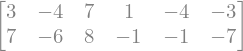

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Markdown, display

import sympy as sp
from sympy import (
    Matrix, Rational, GramSchmidt, N, eye,
    init_printing, simplify, sqrt, zeros
)

init_printing()
np.set_printoptions(precision=6, suppress=True)

# 各列が1個のデータ点(x_i, y_i)です．
A = Matrix([
    [3, -4, 7, 1, -4, -3],
    [7, -6, 8, -1, -1, -7],
])
x = A.row(0).T
y = A.row(1).T
n = A.cols

figure_candidates = [
    Path('svd_vs_qr'),
    Path('d5_la_basic/hidden_files/svd_vs_qr'),
]
figure_dir = next((p for p in figure_candidates if p.exists()),
                  figure_candidates[0])
figure_dir.mkdir(parents=True, exist_ok=True)

print('A.shape =', A.shape)
print('各行の平均 =',
      [Rational(sum(A.row(i)), n) for i in range(A.rows)])
display(A)

## 行列の次元を描く関数

予習宿題で使った`draw_matrix_equation_dimensions`を，この課題でも利用します．ここではSVDに必要な通常行列と対角行列を描ける版を用意します．行列のshapeにはSymPyの`Matrix.shape`またはNumPy配列の`shape`をそのまま渡せます．

In [2]:
def draw_matrix_equation_dimensions(factors, operators, title=None):
    """行列積の各因子をshapeつきの長方形で描きます．

    factorsの要素は(rows, columns, label, color[, pattern])です．
    patternには次を指定できます．

    - 'dense'：通常の密行列
    - 'diagonal'：対角行列
    - ('null_columns', rank)：先頭rank列を主要部，後半を零空間基底として薄色表示
    - ('active_columns', rank)：先頭rank列だけが非零で，後半が0列
    """
    if len(operators) != len(factors) - 1:
        raise ValueError('operatorsはfactorsより1個少なくしてください．')

    parsed = []
    for factor in factors:
        if len(factor) == 4:
            rows, columns, label, color = factor
            pattern, pattern_rank = 'dense', min(rows, columns)
        elif len(factor) == 5:
            rows, columns, label, color, pattern_spec = factor
            if isinstance(pattern_spec, tuple):
                pattern, pattern_rank = pattern_spec
            else:
                pattern = pattern_spec
                pattern_rank = min(rows, columns)
        else:
            raise ValueError('factorは4要素または5要素です．')

        allowed = {'dense', 'diagonal', 'null_columns', 'active_columns'}
        if pattern not in allowed:
            raise ValueError(f'未知のpatternです：{pattern}')
        rows, columns = int(rows), int(columns)
        pattern_rank = max(0, min(int(pattern_rank), columns))
        parsed.append((rows, columns, label, color,
                       pattern, pattern_rank))

    gap = 1.35
    positions = []
    cursor = 0.
    for i, (_, columns, _, _, _, _) in enumerate(parsed):
        positions.append(cursor)
        cursor += columns
        if i < len(operators):
            cursor += gap

    max_rows = max(rows for rows, _, _, _, _, _ in parsed)
    top = max_rows/2 + .45
    fig, ax = plt.subplots(figsize=(max(9, .72*cursor), 5))

    for factor, x0 in zip(parsed, positions):
        rows, columns, label, color, pattern, pattern_rank = factor

        if pattern == 'dense':
            facecolor, alpha = color, .45
        else:
            facecolor, alpha = 'whitesmoke', 1.

        ax.add_patch(Rectangle(
            (x0, -rows/2), columns, rows,
            facecolor=facecolor, alpha=alpha,
            edgecolor='.35', linewidth=1.5
        ))

        if pattern == 'diagonal':
            for i in range(min(rows, columns)):
                ax.add_patch(Rectangle(
                    (x0+i, rows/2-i-1), 1, 1,
                    facecolor=color, alpha=.78, edgecolor='none'
                ))

        elif pattern in {'null_columns', 'active_columns'}:
            ax.add_patch(Rectangle(
                (x0, -rows/2), pattern_rank, rows,
                facecolor=color, alpha=.48, edgecolor='none'
            ))
            if pattern == 'null_columns' and columns > pattern_rank:
                # 薄色部分は0列ではなく，Aで0へ写る零空間基底です．
                ax.add_patch(Rectangle(
                    (x0+pattern_rank, -rows/2),
                    columns-pattern_rank, rows,
                    facecolor=color, alpha=.12, edgecolor='none',
                    hatch='//'
                ))

        ax.text(x0+columns/2, 0, '$' + label + '$',
                ha='center', va='center', fontsize=20)
        ax.text(x0+columns/2, top,
                '$' + str(rows) + r'\times ' + str(columns) + '$',
                color=color, ha='center', fontsize=15)

    for i, operator in enumerate(operators):
        left_x = positions[i] + parsed[i][1]
        ax.text(left_x+gap/2, 0, '$' + operator + '$',
                ha='center', va='center', fontsize=22)

    ax.set_xlim(-.5, cursor+.5)
    ax.set_ylim(-max_rows/2-.5, top+.6)
    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=16)
    plt.show()
    return fig, ax

# 課題1：SymPyのQR分解による最小二乗回帰

予習宿題と同じ流れで，$x$から$y$を予測する直線
$$
\widehat y=\beta_0+\beta_1x
$$
を最小二乗問題の解析解として求めます．

## 1-1　デザイン行列

切片を含むデザイン行列$X$をSymPyの`Matrix`として作り，$X$と$\boldsymbol y$のshapeを確認してください．

## 1-2　QR分解と最小二乗解

回帰直線$\widehat y=\beta_0+\beta_1x$の切片$\beta_0$と傾き$\beta_1$は，データから求める未知パラメータです．これらを
$$
\boldsymbol{\beta}=
\begin{bmatrix}\beta_0\\\beta_1\end{bmatrix}
$$
という1本のベクトルにまとめます．デザイン行列$X$を用いると，$\widehat{\boldsymbol y}=X\boldsymbol{\beta}$は全6点の予測値を並べたベクトルです．したがって，ここでの目的は，$\lVert\boldsymbol y-X\boldsymbol{\beta}\rVert_2^2$を最小にする$\boldsymbol{\beta}$を求めることです．

`X.QRdecomposition()`でreduced QR分解$X=QR$を求め，逆行列を作らずに
$$
R\boldsymbol{\beta}=Q^T\boldsymbol y
$$
を`R.LUsolve(Q.T*y)`で解いてください．

## 1-3　予測値と残差

$\widehat{\boldsymbol y}=X\boldsymbol\beta$と残差$\boldsymbol r=\boldsymbol y-\widehat{\boldsymbol y}$を求め，$X^T\boldsymbol r$を表示してください．その結果が零ベクトルになることを目視で確認します．

## 1-4　QR回帰のプロット

データ点，回帰直線，予測点，$y$方向の残差を同じ図に描いてください．SymPyで求めた解析解は記号式のまま保ち，Matplotlibへ渡す直前にだけ`float`へ変換します．

## 1-5　最小二乗損失

縦残差平方和$\lVert\boldsymbol y-X\boldsymbol\beta\rVert_2^2$をSymPyの記号計算で求めてください．

# 課題2：NumPyのSVDと特異成分

中心化されたデータ行列
$$
A=
\begin{bmatrix}
3&-4&7&1&-4&-3\\
7&-6&8&-1&-1&-7
\end{bmatrix}
$$
を，まずNumPyのSVDで分解します．

ここまでSymPyで計算すると，結果がきれいな分数になって気持ちいいでしょう．でも，SVDでは4桁程度の浮動小数点数で値を確認する方が分かりやすいです．ここでSymPyの行列$A$をNumPy配列`A_np`へ変換します．`np.linalg.svd`は特異値を大きい順で返すため，sortは不要です．

## 2-1　SVDによる分解

`np.linalg.svd(A_np, full_matrices=True)`で
$$
A=U\Sigma V^T
$$
を求めてください．NumPyの`sigma`は特異値を大きい順で返します．この課題では実数行列だけを扱うため，NumPyが返す第3の行列を`Vt`とし，数式の$V^T$に対応させます．各行列と特異値のshapeを確認してください．

## 2-2　特異成分$a_1$，$a_2$による$A$の再構成

SVDを特異値ごとに分けると，
$$
A=a_1+a_2，\qquad
a_i=\sigma_i\boldsymbol u_i\boldsymbol v_i^T
$$
です．$a_1$と$a_2$は，$2\times1$列ベクトルと$1\times6$行ベクトルの積なので外積となり，$2\times6$のランク1行列が得られます．

内積と外積，行列積のSymPy, NumPyのコード対応は次のとおりです．

| 演算 | 数式 | SymPy | NumPy |
|:--|:--|:--|:--|
| 内積 | $u^Tv$ | `u.dot(v)` | `u @ v` または `np.dot(u, v)` |
| 外積 | $uv^T$ | `u * v.T` | `np.outer(u, v)` |
| 行列積 | $AB$ | `A * B` | `A @ B` |

表の`u`，`v`はベクトル，`A`，`B`は行列です．NumPyの1次元配列では`.T`を付けてもshapeは変わらないため，外積には`np.outer`を使います．一方，`U[:, [0]]`のように2次元の列として取り出せば，`U[:, [0]] @ Vt[[0], :]`は$2\times1$行列と$1\times6$行列の積，すなわち外積になります．なお，NumPyの`A * B`は行列積ではなく，要素ごとの積です．

$a_1,a_2$は，それぞれ`Vt`の第1行，第2行を使って作ります．$a_1+a_2$を表示し，$A$が再構成されることを目視で確認してください．

## 2-3　特異成分とデータ点のプロット

$A$の各列は元のデータ点，$a_1$の各列はその点を第1特異ベクトル$\boldsymbol u_1$の直線へ直交射影した点です．元の点から$a_1$の点への残差ベクトルを描き，第1・第2特異ベクトルの方向も示してください．

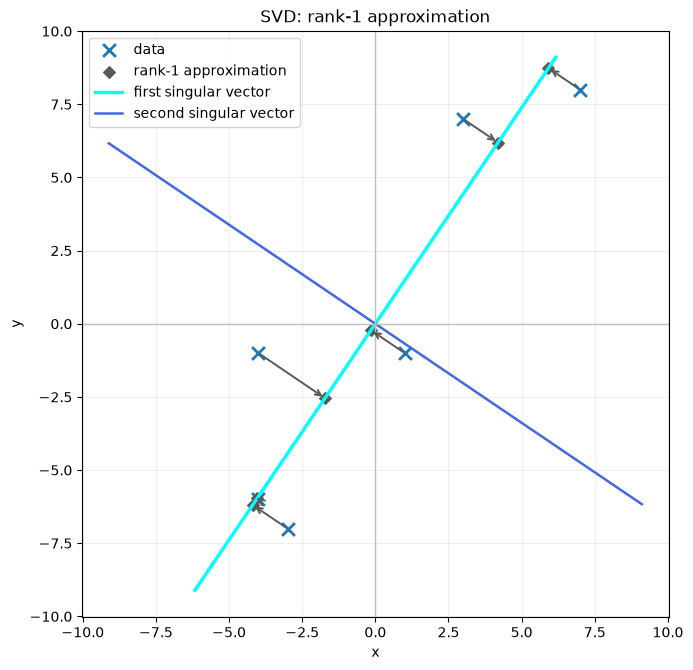

saved: svd_vs_qr/pca_projection_sp.png


In [10]:
t = np.linspace(-11, 11, 300)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(A_np[0], A_np[1], marker='x', s=85,
           linewidths=2, color='tab:blue', label='data')
ax.scatter(a1[0], a1[1], marker='D', s=35,
           color='0.35', label='rank-1 approximation')
for i in range(n):
    ax.annotate('', xy=a1[:, i], xytext=A_np[:, i],
                arrowprops=dict(arrowstyle='->',
                                color='0.35', lw=1.4))
ax.plot(t*u1[0], t*u1[1], color='cyan',
        lw=2.4, label='first singular vector')
ax.plot(t*u2[0], t*u2[1], color='royalblue',
        lw=1.8, label='second singular vector')
ax.axhline(0, color='0.75', lw=1)
ax.axvline(0, color='0.75', lw=1)
ax.set(xlabel='x', ylabel='y',
       title='SVD: rank-1 approximation')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()

pca_plot_path = figure_dir / 'pca_projection_sp.png'
fig.savefig(pca_plot_path, dpi=180, bbox_inches='tight')
plt.show()
print('saved:', pca_plot_path)

## 2-4　$AV=U\Sigma$で見るSVDの次元対応

`full_matrices=True`で得た`Vt`は，数式の$V^T$に対応する$6\times6$行列です．したがって，`Vt.T`が$V$であり，
$$
AV=U\Sigma
$$
となります．`draw_matrix_equation_dimensions`を使い，
$$
A_{2\times6}V_{6\times6}
=
U_{2\times2}\Sigma_{2\times6}
$$
を1枚の図にしてください．

`Vt.T`，すなわち$V$の第3列以降は0ベクトルではありませんが，$A$の零空間$\operatorname{Ker}(A)$の正規直交基底なので，
$$
A\boldsymbol v_3=\cdots=A\boldsymbol v_6=\boldsymbol0
$$
となります．`A_np @ Vt.T`を`.round(4)`で表示し，その後半4列がほぼ0になることを目視で確認してください．また，$V$は直交行列なので，`Vt.T @ Vt`が単位行列になることも4桁表示で目視確認してください．図では，$V$の後半4列を「$A$で0へ写る列」として薄色の斜線で示し，$AV$と$\Sigma$の後半4列を実際の0列として薄色表示してください．

# 課題3：共分散行列とPCA

## 3-1　共分散行列の固有値，固有ベクトル

データが中心化済みであることを確認し，標本共分散行列
$$
S=\frac{1}{n-1}AA^T
$$
を作り，その固有値，固有ベクトルを求めなさい．得られた固有値と，課題2のSVDで求めたsingular valueを4桁程度で並べ，目視で比べてください．値そのものは同じではなく，両者には
$$
\lambda_i=\frac{\sigma_i^2}{n-1}
$$
という関係があります．そこで，`sigma**2/(n-1)`も表示し，固有値と目視で比較します．`np.linalg.eigh`の固有値は小さい順，SVDのsingular valueは大きい順に並ぶため，今回は`eigvals[1]`と`sigma[0]**2/(n-1)`，`eigvals[0]`と`sigma[1]**2/(n-1)`がそれぞれ対応します．

対角成分$S_{11},S_{22}$は$x,y$の分散，非対角成分$S_{12}=S_{21}$は共分散です．

## 3-2　固有ベクトルとSVDの左特異ベクトル

共分散行列$S$の固有ベクトルと，SVDで得た$U$の列を比較してください．並び順が逆なので，`eigvecs[:, 1]`と`U[:, 0]`，`eigvecs[:, 0]`と`U[:, 1]`がそれぞれ対応します．固有ベクトルは符号が一意ではないため，対応するベクトルが正負逆になることがあります．しかし，$u$と$-u$は同じ直線方向を表します．数値を4桁程度で表示し，目視で確認してください．


# 課題4：PCAの直交射影とQR回帰との比較

## 4-1　QR回帰とPCAを並べる（準備済みコード）

左にPCAの直交残差，右にQR回帰の縦残差を描く比較図です．描画処理が長いため，pickerで課題用ノートを作る場合にも，直後のコードセルはそのまま残します．

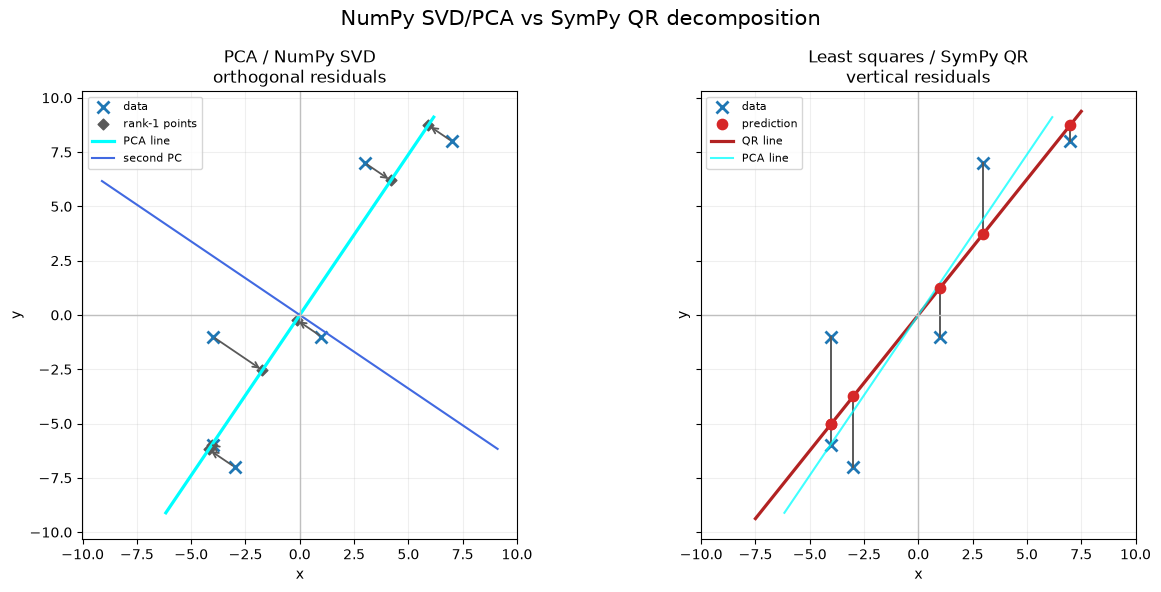

saved: svd_vs_qr/svd_qr_comparison_sp.png


In [14]:
t = np.linspace(-11, 11, 300)

fig, axes = plt.subplots(1, 2, figsize=(13, 6),
                         sharex=True, sharey=True)

ax = axes[0]
ax.scatter(A_np[0], A_np[1], marker='x', s=75,
           linewidths=2, color='tab:blue', label='data')
ax.scatter(a1[0], a1[1], marker='D', s=30,
           color='0.35', label='rank-1 points')
for i in range(n):
    ax.annotate('', xy=a1[:, i], xytext=A_np[:, i],
                arrowprops=dict(arrowstyle='->',
                                color='0.35', lw=1.3))
ax.plot(t*u1[0], t*u1[1], color='cyan',
        lw=2.3, label='PCA line')
ax.plot(t*u2[0], t*u2[1], color='royalblue',
        lw=1.5, label='second PC')
ax.set_title('PCA / NumPy SVD\northogonal residuals')

ax = axes[1]
ax.scatter(x_plot, y_plot, marker='x', s=75,
           linewidths=2, color='tab:blue', label='data')
ax.scatter(x_plot, y_hat_plot, s=55, color='tab:red',
           zorder=3, label='prediction')
for xi, yi, yhi in zip(x_plot, y_plot, y_hat_plot):
    ax.plot([xi, xi], [yi, yhi], color='0.35', lw=1.4)
ax.plot(x_line, beta0+beta1*x_line,
        color='firebrick', lw=2.3, label='QR line')
ax.plot(t*u1[0], t*u1[1], color='cyan',
        lw=1.5, alpha=.75, label='PCA line')
ax.set_title('Least squares / SymPy QR\nvertical residuals')

for ax in axes:
    ax.axhline(0, color='0.75', lw=1)
    ax.axvline(0, color='0.75', lw=1)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)

fig.suptitle('NumPy SVD/PCA vs SymPy QR decomposition',
             fontsize=15)
fig.tight_layout()

comparison_path = figure_dir / 'svd_qr_comparison_sp.png'
fig.savefig(comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print('saved:', comparison_path)

## 4-2　二つの最小化問題

QR回帰の直線とPCAの直線について，縦残差平方和と直交距離平方和を浮動小数点数で計算し，4桁程度で確認してください．

## 4-3　結果の説明

二つの直線の傾きと誤差を比較し，QR回帰とPCAが異なる直線を与える理由を説明してください．

# 付録：Eckart--Young定理と行列間の距離

ここまでは，データ点を表すベクトルと直線との距離を考えてきました．この付録では，その考えを行列全体の距離へ拡張し，SVDの打ち切りが最良ランク1近似を与えることを確認します．ここは新しい課題ではなく，本文の結果を別の視点から読み直すための資料です．

## A-1　ベクトルの距離から行列の距離へ

二つのベクトル$\boldsymbol{x},\boldsymbol{y}\in\mathbb{R}^m$の距離は，通常，Euclidノルム
$$
\lVert\boldsymbol{x}-\boldsymbol{y}\rVert_2
=
\sqrt{\sum_{j=1}^m(x_j-y_j)^2}
$$
で測ります．

同様に，同じshapeを持つ二つの行列$A,B\in\mathbb{R}^{m\times n}$の距離は，Frobeniusノルム
$$
\lVert A-B\rVert_F
=
\sqrt{\sum_{i=1}^m\sum_{j=1}^n(A_{ij}-B_{ij})^2}
$$
で測れます．$A=[\boldsymbol a_1,\ldots,\boldsymbol a_n]$，$B=[\boldsymbol b_1,\ldots,\boldsymbol b_n]$と列ベクトルに分けると，
$$
\lVert A-B\rVert_F^2
=
\sum_{j=1}^n
\lVert\boldsymbol a_j-\boldsymbol b_j\rVert_2^2
$$
です．したがって，行列間の距離は，対応するデータ点どうしの距離の二乗を全点について足したものと考えられます．

## A-2　Eckart--Young定理

SVDは，行列$A$を互いに直交するランク1成分へ分けます．今回のランク2の行列では，
$$
A
=
\sigma_1\boldsymbol u_1\boldsymbol v_1^T
+
\sigma_2\boldsymbol u_2\boldsymbol v_2^T
=
a_1+a_2，
\qquad
\sigma_1\geq\sigma_2\geq0
$$
です．各$a_i$はランク1行列で，そのすべての列は$\boldsymbol u_i$の定数倍です．したがって，ランク1行列でデータを近似することは，データ点を1本の方向だけで表すことに対応します．

Frobeniusノルムには，
$$
\lVert A\rVert_F^2
=
\sigma_1^2+\sigma_2^2
$$
という関係があります．これは，行列全体の「大きさ」が，二つの特異成分の大きさの二乗和に分かれることを意味します．

第1成分だけを残すと，
$$
A_1=a_1=\sigma_1\boldsymbol u_1\boldsymbol v_1^T
$$
となり，捨てた成分は
$$
A-A_1=a_2
$$
です．$\boldsymbol u_2$と$\boldsymbol v_2$は単位ベクトルなので，
$$
\lVert A-A_1\rVert_F
=
\lVert a_2\rVert_F
=
\sigma_2
$$
となります．つまり，第1特異成分だけを残したときの誤差は，捨てた第2特異値そのものです．

ここで，「別のランク1行列を選べば，もっと誤差を小さくできないか」という疑問が生じます．Eckart--Young定理は，任意のランク1以下の行列$B$に対して，
$$
\lVert A-A_1\rVert_F
\leq
\lVert A-B\rVert_F
$$
が成り立つことを保証します．したがって，最も大きい特異値$\sigma_1$に対応する成分を残す$A_1$が，$A$に最も近いランク1行列です．

一般に，特異値を
$$
\sigma_1\geq\sigma_2\geq\cdots\geq0
$$
とすると，最良ランク$k$近似は，大きい方から$k$個の特異成分を残した
$$
A_k
=
\sum_{i=1}^k
\sigma_i\boldsymbol u_i\boldsymbol v_i^T
$$
であり，その誤差は
$$
\lVert A-A_k\rVert_F
=
\sqrt{\sum_{i>k}\sigma_i^2}
$$
です．SVDによる低ランク近似とは，「大きい特異成分を残し，小さい特異成分を捨てる」操作だと解釈できます．

NumPyで誤差の二乗と$\sigma_2^2$を同じ桁数で表示し，値が一致することを目視で確認します．

## A-3　コードによる確認

SVDの第1成分から得た$a_1$について，Frobenius距離と第2特異値を表示し，値が一致することを目視で確認します．また，本文のQR回帰による予測点を列に並べた行列$A_{\mathrm{QR}}$もランク1なので，その距離と比較します．

In [17]:
y_hat_np = np.array([float(v) for v in y_hat])
A_qr_rank1 = np.vstack((x_np, y_hat_np))

frobenius_sq_svd = np.sum((A_np - a1)**2)
frobenius_sq_qr = np.sum((A_np - A_qr_rank1)**2)

print('||A-a1||_F^2 =', round(frobenius_sq_svd, 6))
print('sigma_2^2 =', round(sigma[1]**2, 6))
print('上の2つの値が一致することを目視で確認')
print('||A-A_qr||_F^2 =', round(frobenius_sq_qr, 6))
print('距離の小数表示：')
print('SVD =', round(np.sqrt(frobenius_sq_svd), 6))
print('QR =', round(np.sqrt(frobenius_sq_qr), 6))

||A-a1||_F^2 = 15.37088
sigma_2^2 = 15.37088
上の2つの値が一致することを目視で確認
||A-A_qr||_F^2 = 43.75
距離の小数表示：
SVD = 3.920571
QR = 6.614378


この結果で，SVDの距離は約$3.921$，QR回帰による行列の距離は約$6.614$です．QR回帰は$y$方向の残差を最小にしますが，SVDは$x$方向と$y$方向を対等に扱い，行列全体のFrobenius距離を最小にします．表示された$\lVert A-a_1\rVert_F^2$と$\sigma_2^2$が同じ値になることも確認できます．

## 参考文献

- 予習宿題：`four_spaces_qr.ipynb`の「QR分解による二次関数fitting」．
- Gilbert Strang著，松崎公紀監訳，『ストラング：線形代数とデータサイエンス』，近代科学社，2021，pp.80--81．
- 共分散行列$S=AA^T/(n-1)$，主成分と左特異ベクトルの関係，直交距離を最小化する直線の説明を参照しました．